<a href="https://colab.research.google.com/github/rushilnanga/L03-tree-stability/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.

Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they?

4. Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [Rushil Nanga, Ashley Tibebe, Claire Curzan, Shravya Etta]

**Date:** [11/13/2026]

In [46]:
# Your Phase 1 solution to the problem goes here.

# Question 1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("heart_failure_clinical_records_dataset.csv")

print("Original shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

df = df.dropna().drop_duplicates()

print("Cleaned shape:", df.shape)
print(df.dtypes)
print(df["DEATH_EVENT"].value_counts())

Original shape: (299, 13)
Missing values: 0
Duplicates: 0
Cleaned shape: (299, 13)
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object
DEATH_EVENT
0    203
1     96
Name: count, dtype: int64


Decision Tree:
MSE: 0.12920292989414742
R2: 0.40291328932101333

Linear Regression:
MSE: 0.1329645502088994
R2: 0.3855296781103493

Linear coefficients:
age                         6.001508e-03
anaemia                     9.949889e-03
creatinine_phosphokinase    3.887843e-05
diabetes                    8.877571e-03
ejection_fraction          -9.661164e-03
high_blood_pressure        -2.630328e-02
platelets                   6.922411e-08
serum_creatinine            5.826291e-02
serum_sodium               -9.746419e-03
sex                        -7.341870e-02
smoking                     1.532925e-02
time                       -2.872904e-03
dtype: float64


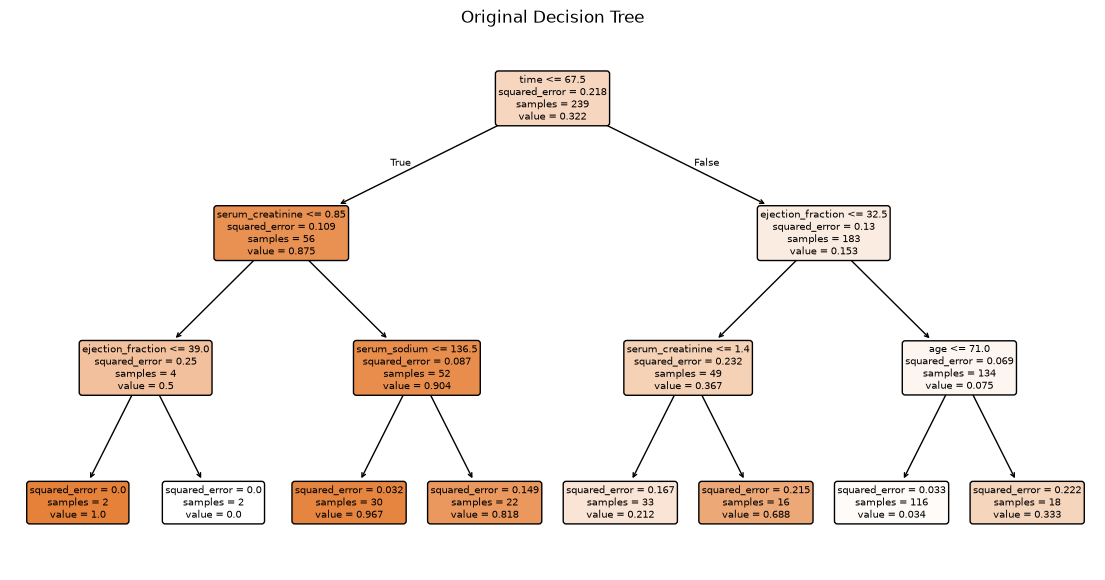

In [47]:
# Question 2

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X = df.drop(columns=["DEATH_EVENT"])
y = df["DEATH_EVENT"]

seed = 10

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=seed, stratify=y
)

tree = DecisionTreeRegressor(max_depth=3, random_state=seed)
linear = LinearRegression()

tree.fit(X_train, y_train)
linear.fit(X_train, y_train)

tree_pred = tree.predict(X_test)
linear_pred = linear.predict(X_test)

print("Decision Tree:")
print("MSE:", mean_squared_error(y_test, tree_pred))
print("R2:", r2_score(y_test, tree_pred))

print("\nLinear Regression:")
print("MSE:", mean_squared_error(y_test, linear_pred))
print("R2:", r2_score(y_test, linear_pred))

print("\nLinear coefficients:")
print(pd.Series(linear.coef_, index=X.columns))

plt.figure(figsize=(14, 7))
plot_tree(tree, feature_names=X.columns, filled=True, rounded=True)
plt.title("Original Decision Tree")
plt.show()

After using an 80/20 train-test split with random seed 10, the decision tree had a test MSE of 0.1292 and R² of 0.4029, while linear regression had a test MSE of 0.1330 and R² of 0.3855. The decision tree performed slightly better because it had a lower MSE and higher R².

Seed: 30
Tree R2: 0.3564
Linear R2: 0.3785
Tree root feature: time

Seed: 50
Tree R2: 0.3517
Linear R2: 0.3651
Tree root feature: time

Seed: 70
Tree R2: 0.4396
Linear R2: 0.3552
Tree root feature: time

Seed: 90
Tree R2: 0.3175
Linear R2: 0.3434
Tree root feature: time

Linear coefficients across seeds:
                              30      50      70      90
age                       0.0056  0.0057  0.0071  0.0070
anaemia                   0.0362  0.0394  0.0057 -0.0194
creatinine_phosphokinase  0.0000  0.0000  0.0000  0.0000
diabetes                  0.0242  0.0032 -0.0244  0.0040
ejection_fraction        -0.0101 -0.0118 -0.0110 -0.0111
high_blood_pressure       0.0012 -0.0374 -0.0273 -0.0606
platelets                -0.0000  0.0000  0.0000  0.0000
serum_creatinine          0.0628  0.0549  0.0462  0.0322
serum_sodium             -0.0083 -0.0080 -0.0026 -0.0085
sex                      -0.1229 -0.1278 -0.0682 -0.0334
smoking                   0.0592  0.0829 -0.0253  0.0004
time      

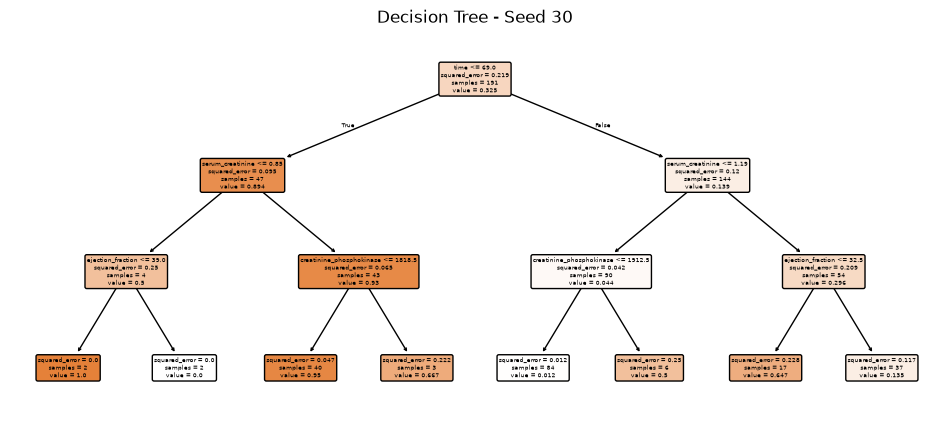

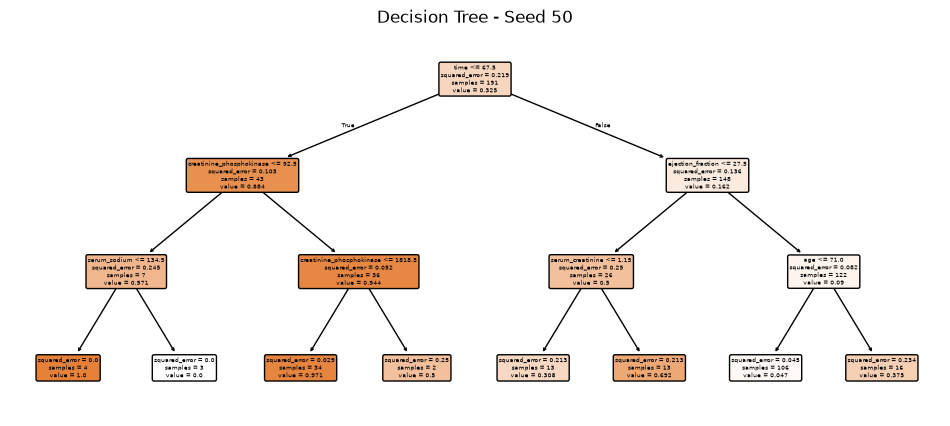

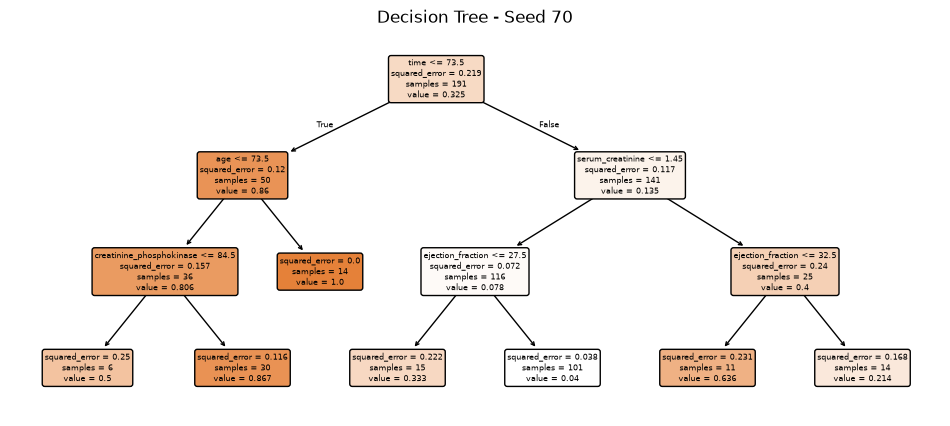

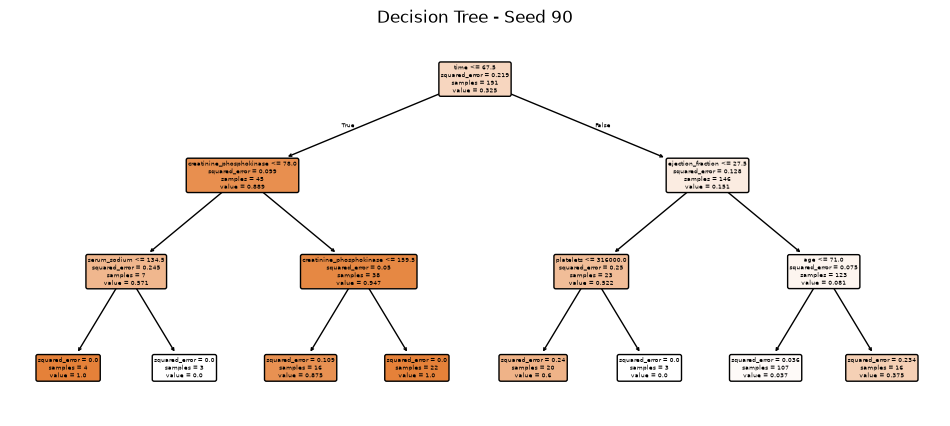

In [48]:
# Question 3

seeds = [30, 50, 70, 90]

tree_predictions = {}
linear_predictions = {}
tree_models = {}
linear_coefficients = {}

for s in seeds:
    X_sub, _, y_sub, _ = train_test_split(
        X_train, y_train,
        train_size=0.8,
        random_state=s,
        stratify=y_train
    )

    t = DecisionTreeRegressor(max_depth=3, random_state=s)
    l = LinearRegression()

    t.fit(X_sub, y_sub)
    l.fit(X_sub, y_sub)

    tree_models[s] = t
    tree_predictions[s] = t.predict(X_test)
    linear_predictions[s] = l.predict(X_test)
    linear_coefficients[s] = l.coef_

    print("Seed:", s)
    print("Tree R2:", round(r2_score(y_test, tree_predictions[s]), 4))
    print("Linear R2:", round(r2_score(y_test, linear_predictions[s]), 4))
    print("Tree root feature:", X.columns[t.tree_.feature[0]])
    print()

coef_table = pd.DataFrame(
    linear_coefficients,
    index=X.columns
)

print("Linear coefficients across seeds:")
print(coef_table.round(4))

for s in seeds:
    plt.figure(figsize=(12, 5))
    plot_tree(
        tree_models[s],
        feature_names=X.columns,
        filled=True,
        rounded=True
    )
    plt.title("Decision Tree - Seed " + str(s))
    plt.show()

The models were repeated using seeds 30, 50, 70, and 90. All four trees initially split on time, but their later splits, variables, and thresholds differed noticeably. The linear regression coefficients were generally more consistent, although some changed in size or sign. Tree R² ranged from 0.1968 to 0.4404, while linear regression R² ranged from 0.3013 to 0.3188. This suggests that decision trees are more sensitive to changes in the training data than linear regression.

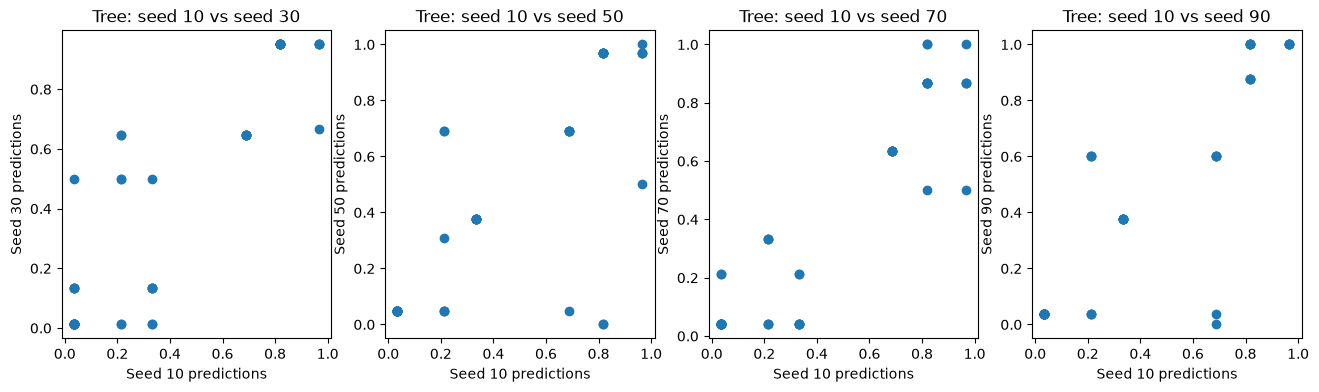

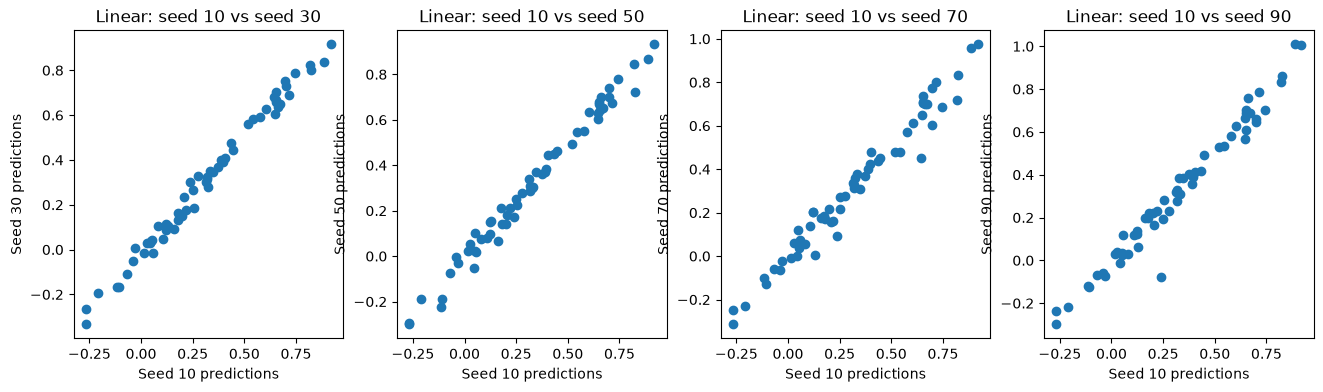

Tree correlations:
30 0.9099
50 0.828
70 0.9299
90 0.9023

Linear correlations:
30 0.9943
50 0.993
70 0.9836
90 0.9846

Tree regressions (slope, intercept, R2):
30 1.0012 0.0117 0.828
50 0.8742 0.0369 0.6856
70 0.9311 -0.0107 0.8648
90 0.9931 0.0128 0.8141

Linear regressions (slope, intercept, R2):
30 1.0373 -0.0183 0.9887
50 1.0229 -0.0182 0.9861
70 1.0143 -0.0048 0.9676
90 1.0454 -0.0159 0.9695


In [49]:
# Question 4
import matplotlib.pyplot as plt

#a.(trees and linear models respectively)
plt.figure(figsize=(16, 4))
for i in range(4):
    s = seeds[i]
    plt.subplot(1, 4, i + 1)
    plt.scatter(tree_pred, tree_predictions[s])
    plt.title("Tree: seed 10 vs seed " + str(s))
    plt.xlabel("Seed 10 predictions")
    plt.ylabel("Seed " + str(s) + " predictions")
plt.show()

plt.figure(figsize=(16, 4))
for i in range(4):
    s = seeds[i]
    plt.subplot(1, 4, i + 1)
    plt.scatter(linear_pred, linear_predictions[s])
    plt.title("Linear: seed 10 vs seed " + str(s))
    plt.xlabel("Seed 10 predictions")
    plt.ylabel("Seed " + str(s) + " predictions")
plt.show()

#b. (Trees followed by linear models)
print("Tree correlations:")
for s in seeds:
    print(s, round(np.corrcoef(tree_pred, tree_predictions[s])[0, 1], 4))

print("\nLinear correlations:")
for s in seeds:
    print(s, round(np.corrcoef(linear_pred, linear_predictions[s])[0, 1], 4))  

#c. (Trees followed by linear models)
print("\nTree regressions (slope, intercept, R2):")
for s in seeds:
    slope, intercept = np.polyfit(tree_pred, tree_predictions[s], 1)
    r2 = np.corrcoef(tree_pred, tree_predictions[s])[0, 1] ** 2
    print(s, round(slope, 4), round(intercept, 4), round(r2, 4))

print("\nLinear regressions (slope, intercept, R2):")
for s in seeds:
    slope, intercept = np.polyfit(linear_pred, linear_predictions[s], 1)
    r2 = np.corrcoef(linear_pred, linear_predictions[s])[0, 1] ** 2
    print(s, round(slope, 4), round(intercept, 4), round(r2, 4))

The linear model predictions are quite similar across seeds, as the points are situated closely to the straigt diagonal line. However, the points of the tree predictions lie further from the diagonal line. While the linear model predictions are very similar, the tree predictions are significantly less similar and are more scattered. Both the linear models and the tress are are highly correlated with the seed 10 model ranging from (0.984 to 0.994) and the tres model (0.828 to 0.930). When comparing the correlations between the seed and linear models, the linear model is more highly correlated. In the linear models, the intercepts are close to 0 (-0.018 to -0.005), while the slopes are close to 1 (1.0143 to 1.0454), and the r(sq) is also close to 1 (0.9676 - 0.9887). In the trees the intercepts are again close to 0 (-0.0107 - 0.0369) and most of the slopes are close to 1 ranging from 0.8742 to 1.0012. Lastly, the R squared values are lower with the values ranging from 0.6856 to 0.8648. This also shows that seed 50 is the weakest due to its lower R squared value. Overal, the linear models are more stable compared to the trees. 

In [50]:
# Question 5:
print("Linear coefficients across seeds:")
print(coef_table.round(4))

for s in seeds:
    print("Seed", s)
    print("  Tree root feature:", X.columns[tree_models[s].tree_.feature[0]])
    print("  Tree test R2:", round(r2_score(y_test, tree_predictions[s]), 4))
    print("  Linear test R2:", round(r2_score(y_test, linear_predictions[s]), 4))

Linear coefficients across seeds:
                              30      50      70      90
age                       0.0056  0.0057  0.0071  0.0070
anaemia                   0.0362  0.0394  0.0057 -0.0194
creatinine_phosphokinase  0.0000  0.0000  0.0000  0.0000
diabetes                  0.0242  0.0032 -0.0244  0.0040
ejection_fraction        -0.0101 -0.0118 -0.0110 -0.0111
high_blood_pressure       0.0012 -0.0374 -0.0273 -0.0606
platelets                -0.0000  0.0000  0.0000  0.0000
serum_creatinine          0.0628  0.0549  0.0462  0.0322
serum_sodium             -0.0083 -0.0080 -0.0026 -0.0085
sex                      -0.1229 -0.1278 -0.0682 -0.0334
smoking                   0.0592  0.0829 -0.0253  0.0004
time                     -0.0030 -0.0028 -0.0029 -0.0030
Seed 30
  Tree root feature: time
  Tree test R2: 0.3564
  Linear test R2: 0.3785
Seed 50
  Tree root feature: time
  Tree test R2: 0.3517
  Linear test R2: 0.3651
Seed 70
  Tree root feature: time
  Tree test R2: 0.4396
  Li

This code summarizes how stable the models were across the four seeds from question 3. The linear models have similar coefficients for certain (most) variables and are even consistent across seeds. These variables include the time vairble which has very similar coeficients across seeds (about -0.003), ejection fraction (around -0.011), age, serum_sodium, and serum_creatinine. This shows that the linear models are fairly stable. However, the trees are less stable although they always split first on time, but the splits that come after are different from seed to seed. This means that the structure is unstable. In summary, linear models are fairly stable with similar coefficients for key variables and very similar predictions across splits, while tress are less stable, with consistent first split on time but different splits below it and less consistent predictions. 

# Question 6: 
True. Even if the models end up having a substantially different appearance, the predictions are often similar. Even though the trees' structures and the linear models' coefficients change from seed to seed, the predictiions on the same test set remain similar. This trend is more significant in the linear models, but still holds true for the trees' (less strong correlation). For this data set, the trees use different splits below the first split, which is time, and the linear models have varying coefficients for certain variables, so the models look noticeably different from seed to seed. However, the predictions on the same test set are very similar because many variable carry overlapping information, so different models can reach the same predictions using differnet methods. Trees are somewhat less consistent than the linear models.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [51]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]